# CommsCube: Energiebedarf

Berechnet die mittlere Stromaufnahme und Laufzeit des CommsCube für mehrere Hardware-Konfigurationen und Nutzungsszenarien.

Grundlage ist die Stückliste `commscube_bom_voll.xlsx`. Alle Stromwerte sind **Annahmen aus Datenblättern** und müssen am Gerät nachgemessen werden. Sie stehen gesammelt in Abschnitt 2 und lassen sich dort ändern.

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt

## 1. Akku

Soldered 333290, Li-Ion, 10 000 mAh, 3,7 V.

Nicht die ganze Kapazität ist nutzbar: Entladeschlussspannung, Alterung und Kälte kosten Kapazität. Der Abschlag `NUTZBAR` ist eine Annahme.

Die Module laufen mit 3,3 V aus einem Linearregler auf der RAK19001-Basis (Annahme). Ein Linearregler nimmt am Eingang etwa denselben Strom auf, den er abgibt. Hinzu kommt sein Eigenverbrauch, hier 5 %. Der Akkustrom ist damit der Laststrom geteilt durch 0,95.

Unter etwa 3,4 V Akkuspannung hält der Regler die 3,3 V nicht mehr. Diese Restladung steckt im Abschlag `NUTZBAR`.

In [2]:
AKKU_MAH = 10_000
AKKU_V = 3.7
NUTZBAR = 0.85                 # Anteil der Nennkapazität, Annahme
REGLER_WIRKUNGSGRAD = 3.3/3.7 * 0.95  # ergibt Akkustrom = Laststrom / 0,95, also 5 % Eigenverbrauch des Linearreglers
LAST_V = 3.3

NUTZBAR_MAH = AKKU_MAH * NUTZBAR


def akkustrom(last_ma):
    """Rechnet einen Laststrom bei 3,3 V auf den Akkustrom um."""
    return last_ma * LAST_V / (AKKU_V * REGLER_WIRKUNGSGRAD)


print(f"Nutzbare Ladung: {NUTZBAR_MAH:.0f} mAh")

Nutzbare Ladung: 8500 mAh


## 2. Komponenten

Stromaufnahme je Betriebszustand in mA bei 3,3 V. Werte sind Richtwerte aus den Datenblättern und **nicht gemessen**.

| Modul | Teil | Quelle der Annahme |
|---|---|---|
| RAK4631 | nRF52840 + SX1262 | Datenblatt nRF52840 |
| RAK3312 | ESP32-S3 + SX1262 | Datenblatt ESP32-S3 |
| LoRa | SX1262 (in beiden Cores) | Datenblatt SX1262, Sendeleistung 22 dBm |
| RAK12501 | Quectel L76K | Datenblatt L76K, prüfen |
| E-Paper | WeAct 4,2", 400 × 300 | Erfahrungswert, messen |
| Tastatur | RAK14004 + RAK14010 | Annahme, messen |
| Summer | RAK18001, MLT-5020 | Annahme, messen |
| Basis | RAK19001 | Ruhestrom Regler, Annahme |
| USB-Board | Typ noch offen, I²C | Platzhalter |

In [3]:
KOMPONENTEN = {
    # Mikrocontroller: aktiv = rechnet, schlaf = wartet auf Ereignis, ble = Zusatz bei aktivem Bluetooth
    "RAK4631": {"aktiv": 3.3, "schlaf": 0.003, "ble": 0.6},
    "RAK3312": {"aktiv": 40.0, "schlaf": 0.25, "ble": 15.0},
    # Funkchip
    "SX1262": {"empfang": 5.3, "senden": 118.0},
    # GNSS
    "RAK12501": {"suche": 41.0, "verfolgung": 30.0, "backup": 0.015},
    # Anzeige
    "E-Paper": {"umschalten": 8.0, "ruhe": 0.001},
    # Bedienung und Ausgabe
    "Tastatur": {"aktiv": 1.0, "ruhe": 0.05},
    "Summer": {"an": 30.0},
    # Basis und Zusatz
    "RAK19001": {"ruhe": 0.05},
    "USB-Board": {"bereit": 1.0},
}

# Zeiten je Ereignis in Sekunden
E_PAPER_UMSCHALTEN_S = 1.5    # Mittel aus Teil- und Vollbild
CPU_JE_PAKET_S = 0.05         # Verarbeitung eines Pakets
TASTEN_CPU_ANTEIL = 0.10      # Anteil der Tippzeit, in der der Controller wach ist
SUMMER_S = 0.5                # Dauer eines Signaltons
GNSS_FIX_S = 10               # Suche bis zum Fix bei Warmstart

## 3. Sendezeit

Meshtastic nutzt im Preset *Long Fast* SF11, 250 kHz Bandbreite, Coderate 4/5 und 16 Präambelsymbole. Die Sendezeit eines Pakets folgt aus der LoRa-Formel von Semtech (AN1200.13).

Ein Meshtastic-Paket besteht aus 16 Byte Kopf und der verschlüsselten Nutzlast. Für eine kurze Textnachricht werden 70 Byte angenommen.

In [4]:
def sendezeit_s(nutzlast_byte, sf=11, bw_hz=250_000, cr_nenner=5, praeambel=16, crc=True, expliziter_kopf=True):
    """Sendezeit eines LoRa-Pakets nach Semtech AN1200.13."""
    t_sym = 2**sf / bw_hz
    de = 1 if t_sym > 0.016 else 0          # Low Data Rate Optimization
    ih = 0 if expliziter_kopf else 1
    n_nutz = 8 + max(
        math.ceil((8 * nutzlast_byte - 4 * sf + 28 + 16 * crc - 20 * ih) / (4 * (sf - 2 * de))) * cr_nenner,
        0,
    )
    return (praeambel + 4.25) * t_sym + n_nutz * t_sym


PAKET_BYTE = 70
T_PAKET = sendezeit_s(PAKET_BYTE)
print(f"Sendezeit je Paket ({PAKET_BYTE} Byte, Long Fast): {T_PAKET * 1000:.0f} ms")

Sendezeit je Paket (70 Byte, Long Fast): 764 ms


## 4. Konfigurationen

Die Stückliste enthält beide Cores zum Tauschen. Die Konfigurationen sind nach ihrem Controller benannt:

- **nRF52840**: Core RAK4631
- **ESP32-S3**: Core RAK3312

Dazu kommen das GNSS-Modul und das geplante USB-Board.

Meshtastic lässt den ESP32-S3 im Normalbetrieb dauerhaft wach. Mit Energiesparmodus geht er zwischen Ereignissen in den Light Sleep. Beim nRF52840 schläft der Controller ohnehin zwischen Ereignissen.

In [5]:
KONFIGURATIONEN = {
    "nRF52840":                      {"core": "RAK4631", "gnss": False, "usb": False},
    "nRF52840 + GNSS":               {"core": "RAK4631", "gnss": True,  "usb": False},
    "nRF52840 + GNSS + USB":         {"core": "RAK4631", "gnss": True,  "usb": True},
    "ESP32-S3":                      {"core": "RAK3312", "gnss": False, "usb": False, "light_sleep": False},
    "ESP32-S3 + GNSS":               {"core": "RAK3312", "gnss": True,  "usb": False, "light_sleep": False},
    "ESP32-S3 + GNSS + USB":         {"core": "RAK3312", "gnss": True,  "usb": True,  "light_sleep": False},
    "ESP32-S3 + GNSS + USB, Sparen": {"core": "RAK3312", "gnss": True,  "usb": True,  "light_sleep": True},
}

## 5. Szenarien

Alle Angaben je Stunde.

- **eigene**: selbst gesendete Pakete, inklusive Position und Telemetrie
- **empfangen**: empfangene Pakete
- **weiterleiten**: Pakete, die das Gerät als Knoten erneut sendet
- **anzeige**: Bildwechsel auf dem E-Paper
- **gnss**: `aus`, `periodisch` (Fix alle 15 min) oder `dauernd`
- **tippen_min**: Minuten, in denen getippt wird
- **signale**: Signaltöne des Summers
- **ble**: Bluetooth an

*Ernstfall Dauerbetrieb* bildet den Fall ab, dass das Gerät im Katastrophenfall ununterbrochen läuft, viel Verkehr weiterleitet und die Position laufend verfolgt.

In [6]:
SZENARIEN = {
    "Bereitschaft": dict(eigene=2, empfangen=20, weiterleiten=10, anzeige=5,
                         gnss="aus", tippen_min=1, signale=2, ble=False),
    "Einsatz": dict(eigene=12, empfangen=60, weiterleiten=30, anzeige=40,
                    gnss="periodisch", tippen_min=10, signale=20, ble=False),
    "Ernstfall Dauerbetrieb": dict(eigene=30, empfangen=200, weiterleiten=100, anzeige=120,
                                   gnss="dauernd", tippen_min=20, signale=60, ble=False),
    "Nur Relais": dict(eigene=1, empfangen=200, weiterleiten=100, anzeige=0,
                       gnss="aus", tippen_min=0, signale=0, ble=False),
}

## 6. Berechnung

Für jede Komponente wird der zeitliche Anteil jedes Zustands innerhalb einer Stunde bestimmt und mit dem Strom gewichtet.

In [7]:
STUNDE = 3600


def mittelstrom(konf, sz):
    """Mittlere Stromaufnahme je Komponente in mA bei 3,3 V."""
    k = KOMPONENTEN
    i = {}

    # Funk: senden für eigene und weitergeleitete Pakete, sonst empfangsbereit
    t_senden = (sz["eigene"] + sz["weiterleiten"]) * T_PAKET
    a = t_senden / STUNDE
    i["LoRa"] = a * k["SX1262"]["senden"] + (1 - a) * k["SX1262"]["empfang"]

    # Anzeige
    t_anzeige = sz["anzeige"] * E_PAPER_UMSCHALTEN_S
    a = t_anzeige / STUNDE
    i["E-Paper"] = a * k["E-Paper"]["umschalten"] + (1 - a) * k["E-Paper"]["ruhe"]

    # Mikrocontroller
    core = k[konf["core"]]
    if konf["core"] == "RAK3312" and not konf.get("light_sleep", False):
        t_cpu = STUNDE
    else:
        pakete = sz["eigene"] + sz["empfangen"] + sz["weiterleiten"]
        t_cpu = pakete * CPU_JE_PAKET_S + t_senden + t_anzeige + sz["tippen_min"] * 60 * TASTEN_CPU_ANTEIL
        t_cpu = min(t_cpu, STUNDE)
    a = t_cpu / STUNDE
    i["Controller"] = a * core["aktiv"] + (1 - a) * core["schlaf"] + (core["ble"] if sz["ble"] else 0)

    # GNSS
    if konf["gnss"]:
        g = k["RAK12501"]
        if sz["gnss"] == "dauernd":
            i["GNSS"] = g["verfolgung"]
        elif sz["gnss"] == "periodisch":
            a = 4 * GNSS_FIX_S / STUNDE
            i["GNSS"] = a * g["suche"] + (1 - a) * g["backup"]
        else:
            i["GNSS"] = g["backup"]

    # Tastatur und Summer
    a = sz["tippen_min"] * 60 / STUNDE
    i["Tastatur"] = a * k["Tastatur"]["aktiv"] + (1 - a) * k["Tastatur"]["ruhe"]
    i["Summer"] = sz["signale"] * SUMMER_S / STUNDE * k["Summer"]["an"]

    # Basis und USB-Board
    i["Basis"] = k["RAK19001"]["ruhe"]
    if konf["usb"]:
        i["USB-Board"] = k["USB-Board"]["bereit"]

    return {name: akkustrom(wert) for name, wert in i.items()}


ergebnisse = []
for konf_name, konf in KONFIGURATIONEN.items():
    for sz_name, sz in SZENARIEN.items():
        teile = mittelstrom(konf, sz)
        summe = sum(teile.values())
        ergebnisse.append({
            "Konfiguration": konf_name,
            "Szenario": sz_name,
            "Strom (mA)": summe,
            "Laufzeit (h)": NUTZBAR_MAH / summe,
            **teile,
        })

df = pd.DataFrame(ergebnisse)

## 7. Laufzeit

Laufzeit in Tagen je Konfiguration und Szenario.

In [8]:
tage = df.pivot(index="Konfiguration", columns="Szenario", values="Laufzeit (h)") / 24
tage = tage.loc[list(KONFIGURATIONEN), list(SZENARIEN)]
tage.round(1)

Szenario,Bereitschaft,Einsatz,Ernstfall Dauerbetrieb,Nur Relais
Konfiguration,,,,
nRF52840,58.5,48.6,34.1,42.6
nRF52840 + GNSS,58.3,45.5,8.4,42.5
nRF52840 + GNSS + USB,49.7,40.1,8.2,37.7
ESP32-S3,7.4,7.2,6.8,7.0
ESP32-S3 + GNSS,7.4,7.1,4.2,7.0
ESP32-S3 + GNSS + USB,7.2,7.0,4.2,6.9
"ESP32-S3 + GNSS + USB, Sparen",46.3,32.9,7.4,33.3


In [9]:
strom = df.pivot(index="Konfiguration", columns="Szenario", values="Strom (mA)")
strom = strom.loc[list(KONFIGURATIONEN), list(SZENARIEN)]
strom.round(1)

Szenario,Bereitschaft,Einsatz,Ernstfall Dauerbetrieb,Nur Relais
Konfiguration,,,,
nRF52840,6.1,7.3,10.4,8.3
nRF52840 + GNSS,6.1,7.8,42.0,8.3
nRF52840 + GNSS + USB,7.1,8.8,43.0,9.4
ESP32-S3,48.1,49.2,52.1,50.3
ESP32-S3 + GNSS,48.2,49.7,83.7,50.3
ESP32-S3 + GNSS + USB,49.2,50.8,84.7,51.4
"ESP32-S3 + GNSS + USB, Sparen",7.6,10.8,47.7,10.6


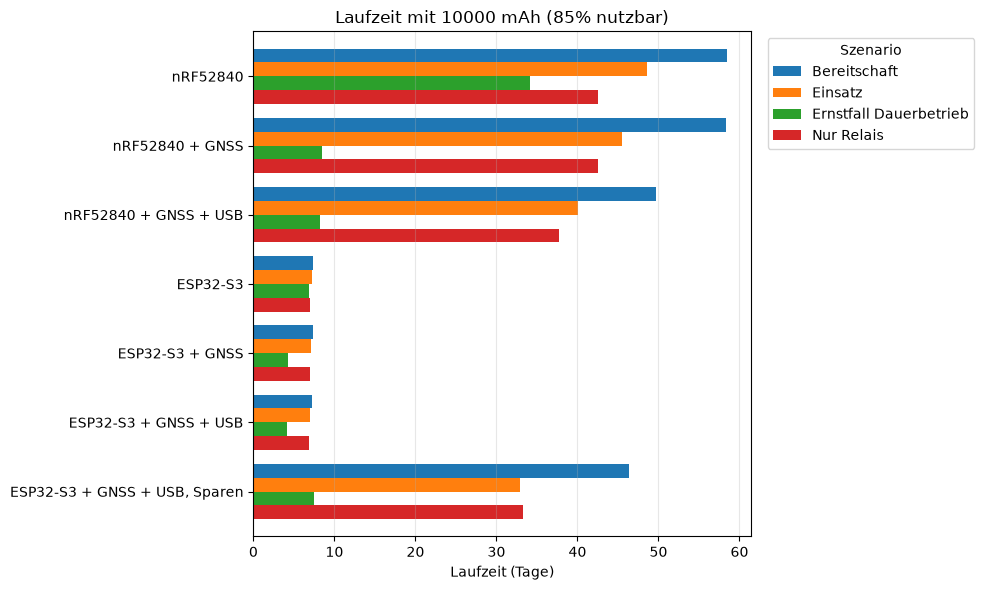

In [10]:
ax = tage.plot.barh(figsize=(10, 6), width=0.8)
ax.set_xlabel("Laufzeit (Tage)")
ax.set_ylabel("")
ax.invert_yaxis()
ax.legend(title="Szenario", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title(f"Laufzeit mit {AKKU_MAH} mAh ({NUTZBAR:.0%} nutzbar)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Aufschlüsselung im Ernstfall

Welche Komponente im Szenario *Ernstfall Dauerbetrieb* wie viel Strom zieht.

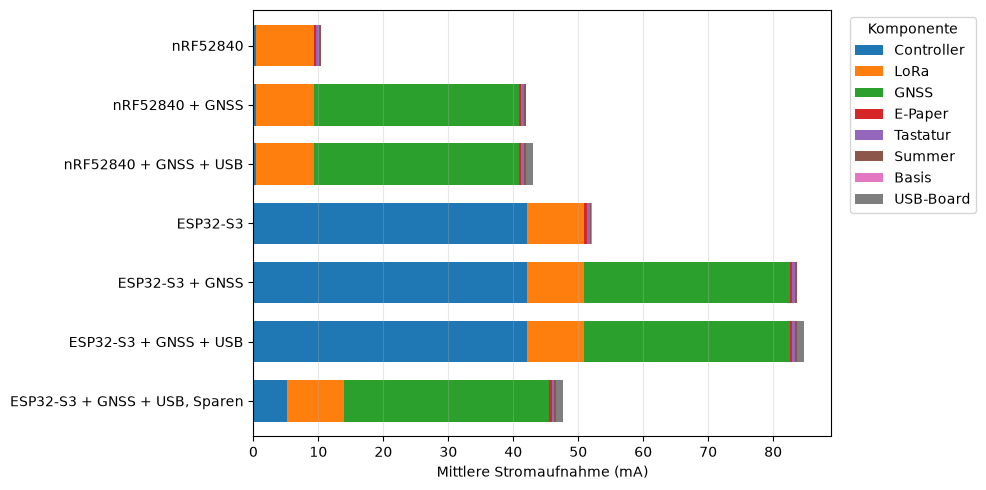

,Controller,LoRa,GNSS,E-Paper,Tastatur,Summer,Basis,USB-Board
Konfiguration,,,,,,,,
nRF52840,0.40,8.85,0.00,0.42,0.39,0.26,0.05,0.00
nRF52840 + GNSS,0.40,8.85,31.58,0.42,0.39,0.26,0.05,0.00
nRF52840 + GNSS + USB,0.40,8.85,31.58,0.42,0.39,0.26,0.05,1.05
ESP32-S3,42.11,8.85,0.00,0.42,0.39,0.26,0.05,0.00
ESP32-S3 + GNSS,42.11,8.85,31.58,0.42,0.39,0.26,0.05,0.00
ESP32-S3 + GNSS + USB,42.11,8.85,31.58,0.42,0.39,0.26,0.05,1.05
"ESP32-S3 + GNSS + USB, Sparen",5.10,8.85,31.58,0.42,0.39,0.26,0.05,1.05


In [11]:
teile = ["Controller", "LoRa", "GNSS", "E-Paper", "Tastatur", "Summer", "Basis", "USB-Board"]
ernst = df[df["Szenario"] == "Ernstfall Dauerbetrieb"].set_index("Konfiguration")[teile].fillna(0)

ax = ernst.plot.barh(stacked=True, figsize=(10, 5), width=0.7)
ax.set_xlabel("Mittlere Stromaufnahme (mA)")
ax.set_ylabel("")
ax.invert_yaxis()
ax.legend(title="Komponente", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

ernst.round(2)

## 9. Duty Cycle

Im Meshtastic-Kanal für EU868 (869,4 bis 869,65 MHz) darf ein Gerät höchstens 10 % der Zeit senden, also 360 s je Stunde.

In [12]:
dc = pd.DataFrame([
    {
        "Szenario": name,
        "Pakete gesendet": sz["eigene"] + sz["weiterleiten"],
        "Sendezeit (s/h)": (sz["eigene"] + sz["weiterleiten"]) * T_PAKET,
    }
    for name, sz in SZENARIEN.items()
])
dc["Duty Cycle (%)"] = dc["Sendezeit (s/h)"] / STUNDE * 100
dc["zulässig"] = dc["Duty Cycle (%)"] <= 10
dc.round(1)

,Szenario,Pakete gesendet,Sendezeit (s/h),Duty Cycle (%),zulässig
0,Bereitschaft,12,9.2,0.3,True
1,Einsatz,42,32.1,0.9,True
2,Ernstfall Dauerbetrieb,130,99.3,2.8,True
3,Nur Relais,101,77.2,2.1,True


## 10. Offene Punkte

- Alle Stromwerte am Gerät messen, besonders E-Paper, Tastatur, Summer und GNSS.
- Typ des USB-Boards klären und Ruhestrom eintragen. Der Wert von 1 mA ist ein Platzhalter.
- Regler der RAK19001 im Schaltplan prüfen. Bei einem Schaltregler sinkt der Akkustrom unter den Laststrom.
- GNSS nicht dauerhaft laufen lassen. Im Ernstfall zieht es mit rund 30 mA mehr als alle anderen Teile zusammen (Abschnitt 8). Ein Fix alle 15 Minuten reicht für die Position meist aus.
- Prüfen, ob Meshtastic auf dem RAK3312 mit Energiesparmodus stabil läuft. Ohne ihn hält der ESP32-S3 nur etwa eine Woche.
- Die Sendeleistung spielt für die Laufzeit kaum eine Rolle. Gesendet wird nur wenige Prozent der Zeit (Abschnitt 9). Der Empfang mit 5,3 mA läuft dagegen ständig.

## 11. Abbildungen für die Poster

Laufzeit der Konfiguration nRF52840 mit GNSS und USB-Board in jedem Szenario, absteigend sortiert, je eine Fassung pro Farbschema der Poster:

| Datei | Poster | Akzentfarbe | Schrift | Größe |
|---|---|---|---|---|
| `bilder/energie_laufzeit_gruen.svg` | Variante 1 | Grün, hsl(140,69°, 75,65 %, 35 %) | Inter | 35 pt |
| `bilder/energie_laufzeit_rot.svg` | Variante 3 | HM-Rot #FC5555 | Libertinus Serif | 38 pt |
| `bilder/energie_laufzeit_rot_breit.svg` | Variante 5 | HM-Rot #FC5555 | Libertinus Serif | 38 pt |
| `bilder/energie_laufzeit_grau.svg` | Variante 4 | Schwarz | TeX Gyre Termes | 39 pt |

Die Balken sind in der Akzentfarbe des jeweiligen Posters gehalten. Beschriftung und Achsen haben die Textfarbe des Posters: #243247 in den Varianten 1, 3 und 5, Schwarz in Variante 4.

Breite und Schriftgröße entsprechen dem Platz und dem Fließtext im jeweiligen Poster. Die Poster binden die SVG ohne Skalierung ein, damit die Schrift im Diagramm genauso groß ist wie im Text.

Die Schrift bleibt in der SVG als Text erhalten. Typst setzt sie beim Einbinden in der Posterschrift, auch wenn matplotlib die Schrift selbst nicht kennt. Für die Abstände nutzt matplotlib eine ähnliche Ersatzschrift.

Die Konfiguration steht nicht in der Abbildung, sondern in der Bildunterschrift. Sie wird aus den Annahmen erzeugt und als `bilder/energie_laufzeit.txt` gespeichert. Im Poster bindet `caption: read("bilder/energie_laufzeit.txt")` sie ein.

Geschätzte Laufzeit mit 10 000-mAh-Akku je Szenario. Controller nRF52840 mit GNSS-Modul und USB-Board. Stromwerte aus Datenblättern.


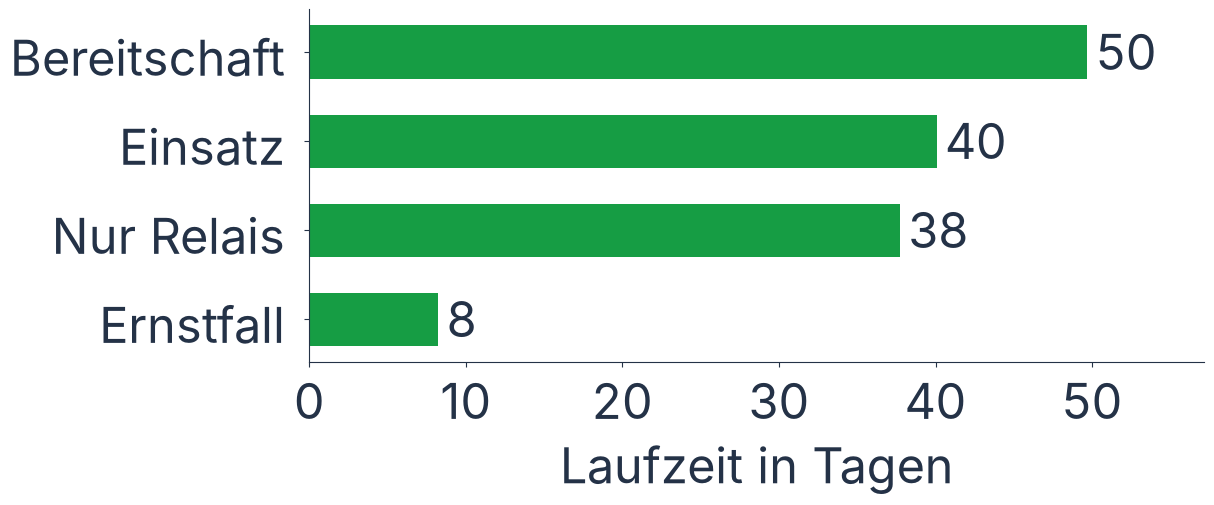

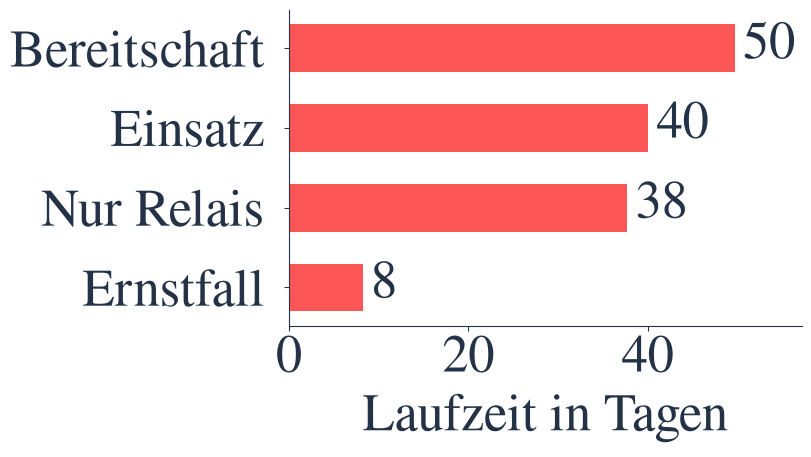

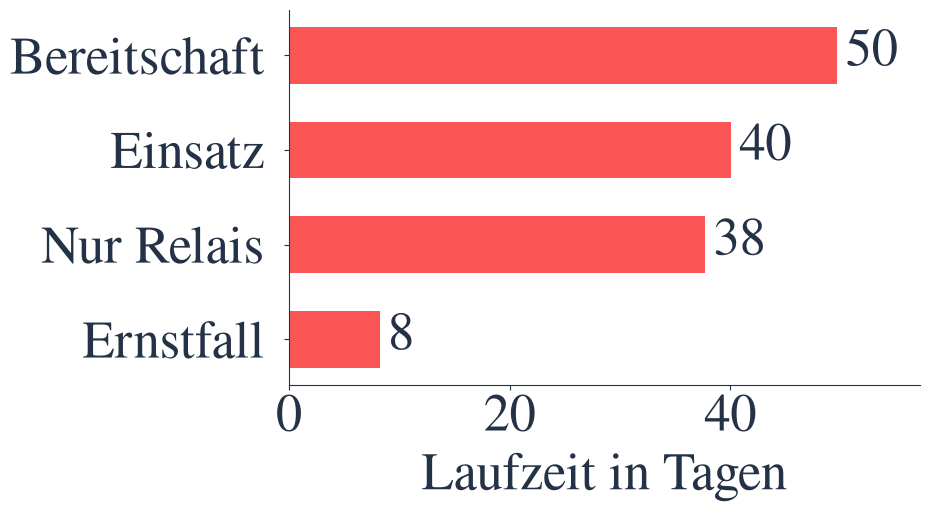

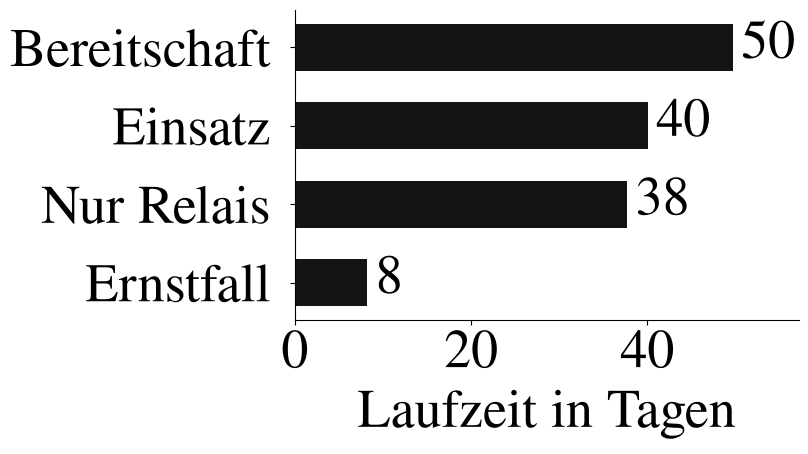

Ernstfall: 43.0 mA, 198 h, nutzbar 8500 mAh


In [13]:
import colorsys
import logging
from matplotlib import font_manager

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
font_manager.fontManager.addfont("/usr/share/fonts/opentype/inter/Inter-Regular.otf")

POSTER_KONF = "nRF52840 + GNSS + USB"

STILE = {
    # Akzentfarbe und Schrift aus dem Poster, Ersatzschrift für die Abstände,
    # Schriftgröße wie der Fließtext und Breite des Platzes im Poster.
    # Das Poster bindet die SVG in Originalgröße ein, so stimmen die Schriftgrößen überein.
    "gruen": {"akzent": colorsys.hls_to_rgb(140.69 / 360, 0.35, 0.7565), "text": "#243247",
              "schrift": ["Inter"], "pt": 35, "breite_cm": 33, "hoehe_cm": 15},
    "rot":   {"akzent": "#FC5555", "text": "#243247", "schrift": ["Libertinus Serif", "Nimbus Roman"],
              "pt": 38, "breite_cm": 23, "hoehe_cm": 14},
    "rot_breit": {"akzent": "#FC5555", "text": "#243247", "schrift": ["Libertinus Serif", "Nimbus Roman"],
                  "pt": 38, "breite_cm": 26, "hoehe_cm": 15.5},
    "grau":  {"akzent": "#141414", "text": "#000000", "schrift": ["TeX Gyre Termes", "Nimbus Roman"],
              "pt": 39, "breite_cm": 23, "hoehe_cm": 14},
}


def tausender(zahl):
    return f"{zahl:,}".replace(",", " ")


bildunterschrift = (
    f"Geschätzte Laufzeit mit {tausender(AKKU_MAH)}-mAh-Akku je Szenario. "
    "Controller nRF52840 mit GNSS-Modul und USB-Board. Stromwerte aus Datenblättern."
)
with open("bilder/energie_laufzeit.txt", "w", encoding="utf-8") as f:
    f.write(bildunterschrift)
print(bildunterschrift)

werte = tage.loc[POSTER_KONF, list(SZENARIEN)].sort_values(ascending=False)  # längste Laufzeit oben

for name, stil in STILE.items():
    with plt.rc_context({
        "font.family": stil["schrift"],
        "font.size": stil["pt"],
        "axes.spines.top": False,
        "axes.spines.right": False,
        "svg.fonttype": "none",
        "svg.hashsalt": "energiebedarf",  # gleiche IDs bei jedem Lauf
        # Beschriftung, Zahlen und Achsen in der Textfarbe des Posters
        "text.color": stil["text"],
        "axes.labelcolor": stil["text"],
        "axes.edgecolor": stil["text"],
        "xtick.color": stil["text"],
        "ytick.color": stil["text"],
    }):
        fig, ax = plt.subplots(figsize=(stil["breite_cm"] / 2.54, stil["hoehe_cm"] / 2.54))
        balken = ax.barh(range(len(werte)), werte, height=0.6, color=stil["akzent"])
        ax.bar_label(balken, fmt="%.0f", padding=6)
        ax.set_yticks(range(len(werte)), [s.replace(" Dauerbetrieb", "") for s in werte.index])
        ax.tick_params(axis="y", pad=14)  # Luft, falls die Posterschrift breiter läuft als die Ersatzschrift
        ax.invert_yaxis()
        ax.set_xlabel("Laufzeit in Tagen")
        ax.set_xlim(0, werte.max() * 1.15)
        fig.tight_layout()
        fig.savefig(f"bilder/energie_laufzeit_{name}.svg", bbox_inches="tight", transparent=True,
                    metadata={"Date": None})  # ohne Zeitstempel, damit unveränderte Grafiken gleich bleiben
        plt.show()

# Werte für den Text auf den Postern
ernst = df[(df["Konfiguration"] == POSTER_KONF) & (df["Szenario"] == "Ernstfall Dauerbetrieb")].iloc[0]
print(f"Ernstfall: {ernst['Strom (mA)']:.1f} mA, {ernst['Laufzeit (h)']:.0f} h, nutzbar {NUTZBAR_MAH:.0f} mAh")